## Asset Class Galaxy


### Settings


In [1]:
# Set refresh_timeseries=True to download timeseries. Otherwise symbol-cache is used.
refresh_timeseries = False
throttle_limit = 100
wait_time = 30


In [2]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}


<IPython.core.display.Javascript object>

### Build asset-classes.csv


AGG AOA AOK AOM AOR BIL BITW BNDX BWX BWZ CANE CORN CPER CTA DBA DBB DBC DBE DBP EBND EEM EFA FXA FXB FXC FXE FXF FXY GLD IBND IEF IEUR IWD IWM IYR JNK JPST LQD MDY PALL PFF PPLT QQQ SLV SPY TIP TLT UGA UNG USO UUP VNQ VOO VPL VTI VTSMX VXUS XLB XLC XLE XLF XLI XLK XLP XLRE XLU XLV XLY 


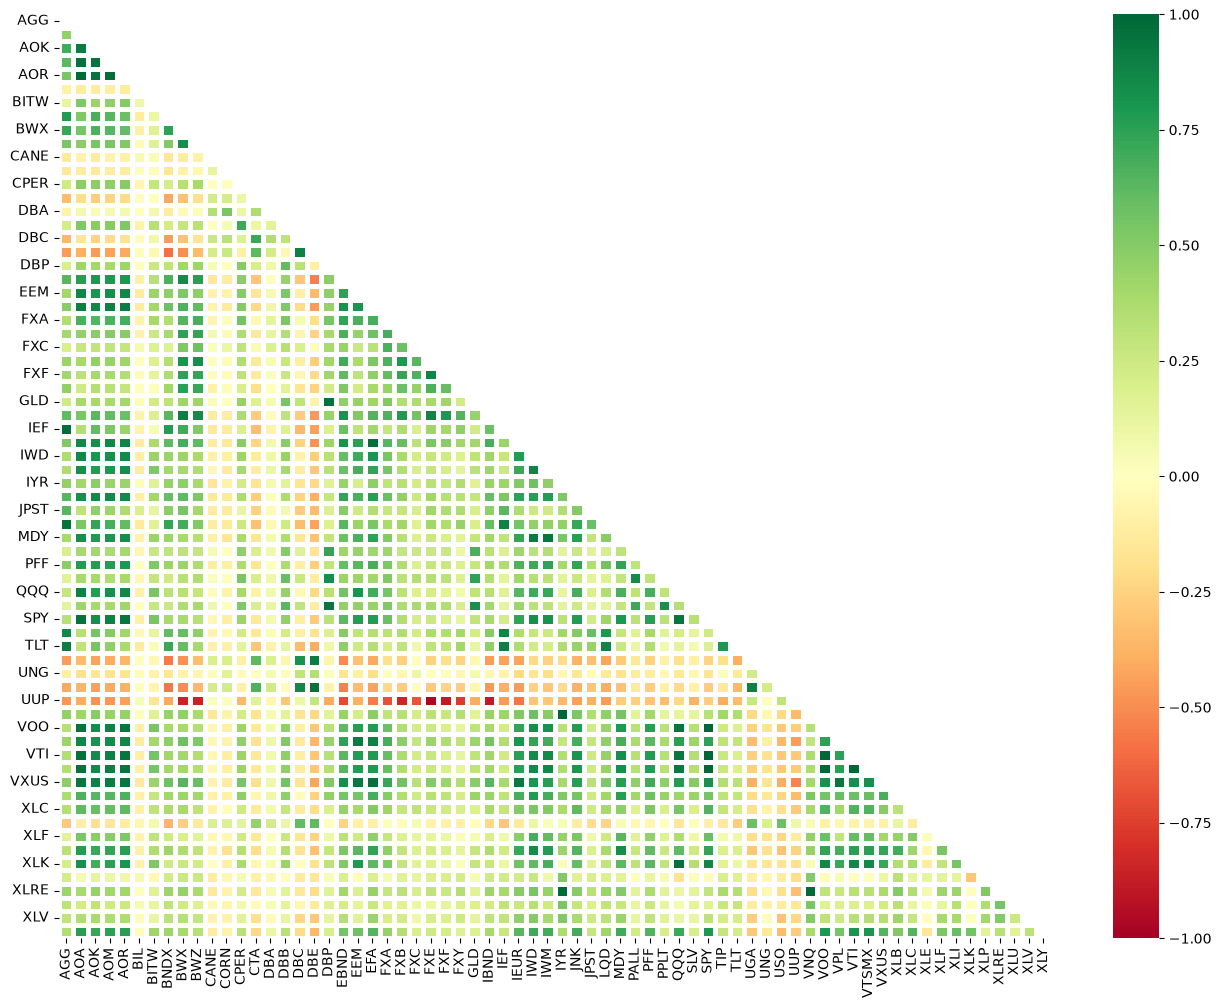

In [3]:
from pathlib import Path

import pandas as pd

import brownbear as bb

bb.notebook_display_options()

directory = Path('.')

# asset2etf maps each asset class to a representative ETF.
asset2etf = pd.read_csv('asset-classes-2-etf.csv', skip_blank_lines=True, comment='#')
asset2etf = asset2etf.set_index(['Asset Class'])['ETF'].to_dict()
symbols = sorted(set(asset2etf.values()))

bb.fetch_timeseries(symbols, refresh=refresh_timeseries, throttle_limit=throttle_limit, wait_time=wait_time)
bb.compile_timeseries(symbols, output_path=directory / 'symbols-timeseries.csv')

df = pd.read_csv('symbols-timeseries.csv', skip_blank_lines=True, comment='#')
df.set_index("Date", inplace=True)

corr_map = bb.correlation_map(df, method='log', days=bb.TRADING_DAYS_PER_YEAR)

with open('asset-classes-in.csv') as f:
    lines = [line.strip() for line in f]

out = []
for line in lines:
    if not line or line.startswith('#'):
        out.append(line)
        continue
    fields = [field.strip() for field in line.split(',')]
    assetA = fields[0].strip('"')
    assetB = fields[1].strip('"')
    if assetA == assetB or assetA == 'Asset Class A':
        out.append(line)
        continue
    etfA = asset2etf[assetA]
    etfB = asset2etf[assetB]
    corrAB = corr_map.loc[etfA, etfB]
    out.append(f'"{assetA}","{assetB}","{corrAB:0.2f}"')

with open('asset-classes.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')


### Build investment-options.csv


In [4]:
import numpy as np

metrics = bb.compute_investment_metrics(df)

with open('investment-options-in.csv') as f:
    out = [line.strip() for line in f]

for asset_class, symbol in asset2etf.items():
    ret_3mo = metrics['annual_returns_3mo'][symbol]
    ret_6mo = metrics['annual_returns_6mo'][symbol]
    ret_1yr = metrics['annual_returns_1yr'][symbol]
    ret_1_1yr = metrics['annual_returns_1_1yr'][symbol]
    ret_3yr = metrics['annual_returns_3yr'][symbol]
    ret_5yr = metrics['annual_returns_5yr'][symbol]
    if np.isnan(ret_3yr):
        ret_3yr = ret_1yr
    if np.isnan(ret_5yr):
        ret_5yr = ret_3yr
    vola = metrics['vola'][symbol] * 100
    ds_vola = metrics['ds_vola'][symbol] * 100
    sd_1yr = metrics['std_dev_1yr'][symbol] * 100
    sd_3yr = metrics['std_dev_3yr'][symbol] * 100
    sd_5yr = metrics['std_dev_5yr'][symbol] * 100
    out.append(
        f'"{asset_class}","{asset_class}","{asset_class}",'
        f'"{ret_3mo:0.2f}","{ret_6mo:0.2f}","{ret_1yr:0.2f}","{ret_1_1yr:0.2f}","{ret_3yr:0.2f}",'
        f'"{ret_5yr:0.2f}","{vola:0.2f}","{ds_vola:0.2f}","{sd_1yr:0.2f}","{sd_3yr:0.2f}","{sd_5yr:0.2f}"'
    )

with open('investment-options.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')

investment_options = pd.read_csv('investment-options.csv', skip_blank_lines=True, comment='#')
investment_options


,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr
0,US Stocks,US Stocks,US Stocks,91.30,18.13,23.33,22.98,20.67,12.34,17.23,11.37,12.37,13.36,16.03
1,Global Stocks,Global Stocks,Global Stocks,70.21,27.57,27.34,27.92,18.53,8.61,23.76,16.38,13.53,12.37,15.06
2,US Bonds,US Bonds,US Bonds,7.67,2.01,4.32,4.58,4.30,0.22,4.00,2.23,2.92,5.49,6.40
3,Global Bonds,Global Bonds,Global Bonds,10.49,2.73,2.49,2.57,4.50,0.52,3.20,1.57,3.07,4.10,5.31
4,Cash Equivalents,Cash Equivalents,Cash Equivalents,3.62,3.63,3.88,3.88,4.63,3.46,0.23,0.04,0.12,0.21,0.55
5,Real Estate,Real Estate,Real Estate,67.78,27.12,15.50,16.00,11.22,2.89,18.27,10.80,13.18,16.64,19.07
6,Commodities,Commodities,Commodities,-30.60,37.75,25.30,25.81,9.42,10.12,18.03,11.63,21.67,15.80,16.60
7,Currencies,Currencies,Currencies,7.84,10.82,8.78,8.69,4.97,5.91,4.87,1.67,6.07,6.82,7.05
8,Managed Futures,Managed Futures,Managed Futures,-41.26,-3.91,1.73,2.07,7.00,7.00,18.01,11.18,18.77,15.15,16.83
9,Balanced,Balanced,Balanced,33.74,9.42,12.37,12.39,10.76,4.88,9.48,5.79,5.94,7.11,8.90
